In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [2]:
df_raw = pd.read_csv("winequality-red.csv", sep=";")

print("Dataset loaded successfully!")
print(f"Rows: {df_raw.shape[0]}")
print(f"Columns: {df_raw.shape[1]}")

display(df_raw.head())

Dataset loaded successfully!
Rows: 1599
Columns: 12


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
print("Dataset shape:", df_raw.shape)
print("\nColumn names:")
print(df_raw.columns.tolist())
print("\nData types and non-null counts:")
df_raw.info()
print("\nMissing values:")
display(df_raw.isnull().sum().to_frame("Missing Values"))
print("\nDuplicate rows:", df_raw.duplicated().sum())
print("\nStatistical summary:")
display(df_raw.describe().T)

Dataset shape: (1599, 12)

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol            

,Missing Values
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0



Duplicate rows: 240

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


In [4]:
df = df_raw.copy()
# Standardize column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)
# Convert columns to numeric
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")
rows_before = len(df)
duplicates_before = df.duplicated().sum()
# Remove duplicate records
df = df.drop_duplicates().copy()
# Remove rows with missing target values
df = df.dropna(subset=["quality"]).copy()
print("Cleaning completed!")
print("Rows before cleaning:", rows_before)
print("Duplicate rows removed:", duplicates_before)
print("Rows after cleaning:", len(df))
print("Columns after cleaning:", len(df.columns))
print("Remaining missing values:", df.isnull().sum().sum())
display(df.head())
assert len(df) >= 1000, "Dataset must contain at least 1,000 rows!"

Cleaning completed!
Rows before cleaning: 1599
Duplicate rows removed: 240
Rows after cleaning: 1359
Columns after cleaning: 12
Remaining missing values: 0


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5


Wine quality score distribution:


,Count
quality,
3,10
4,53
5,577
6,535
7,167
8,17


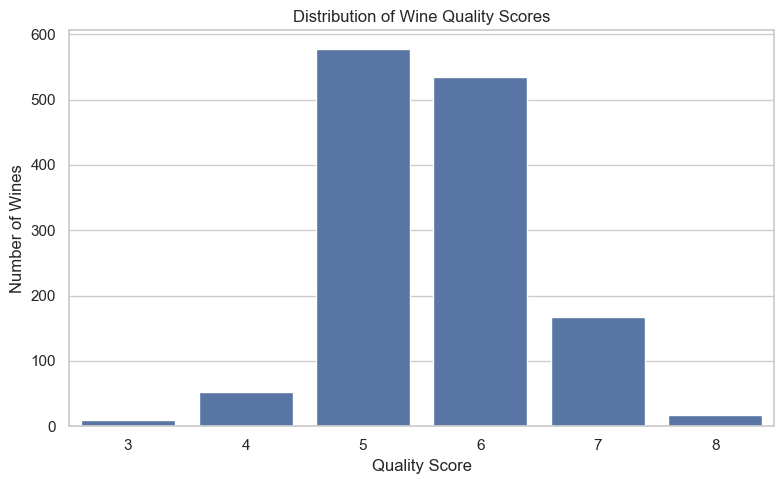

In [5]:
print("Wine quality score distribution:")
display(
    df["quality"]
    .value_counts()
    .sort_index()
    .to_frame("Count")
)
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality")
plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Number of Wines")
plt.tight_layout()
plt.show()

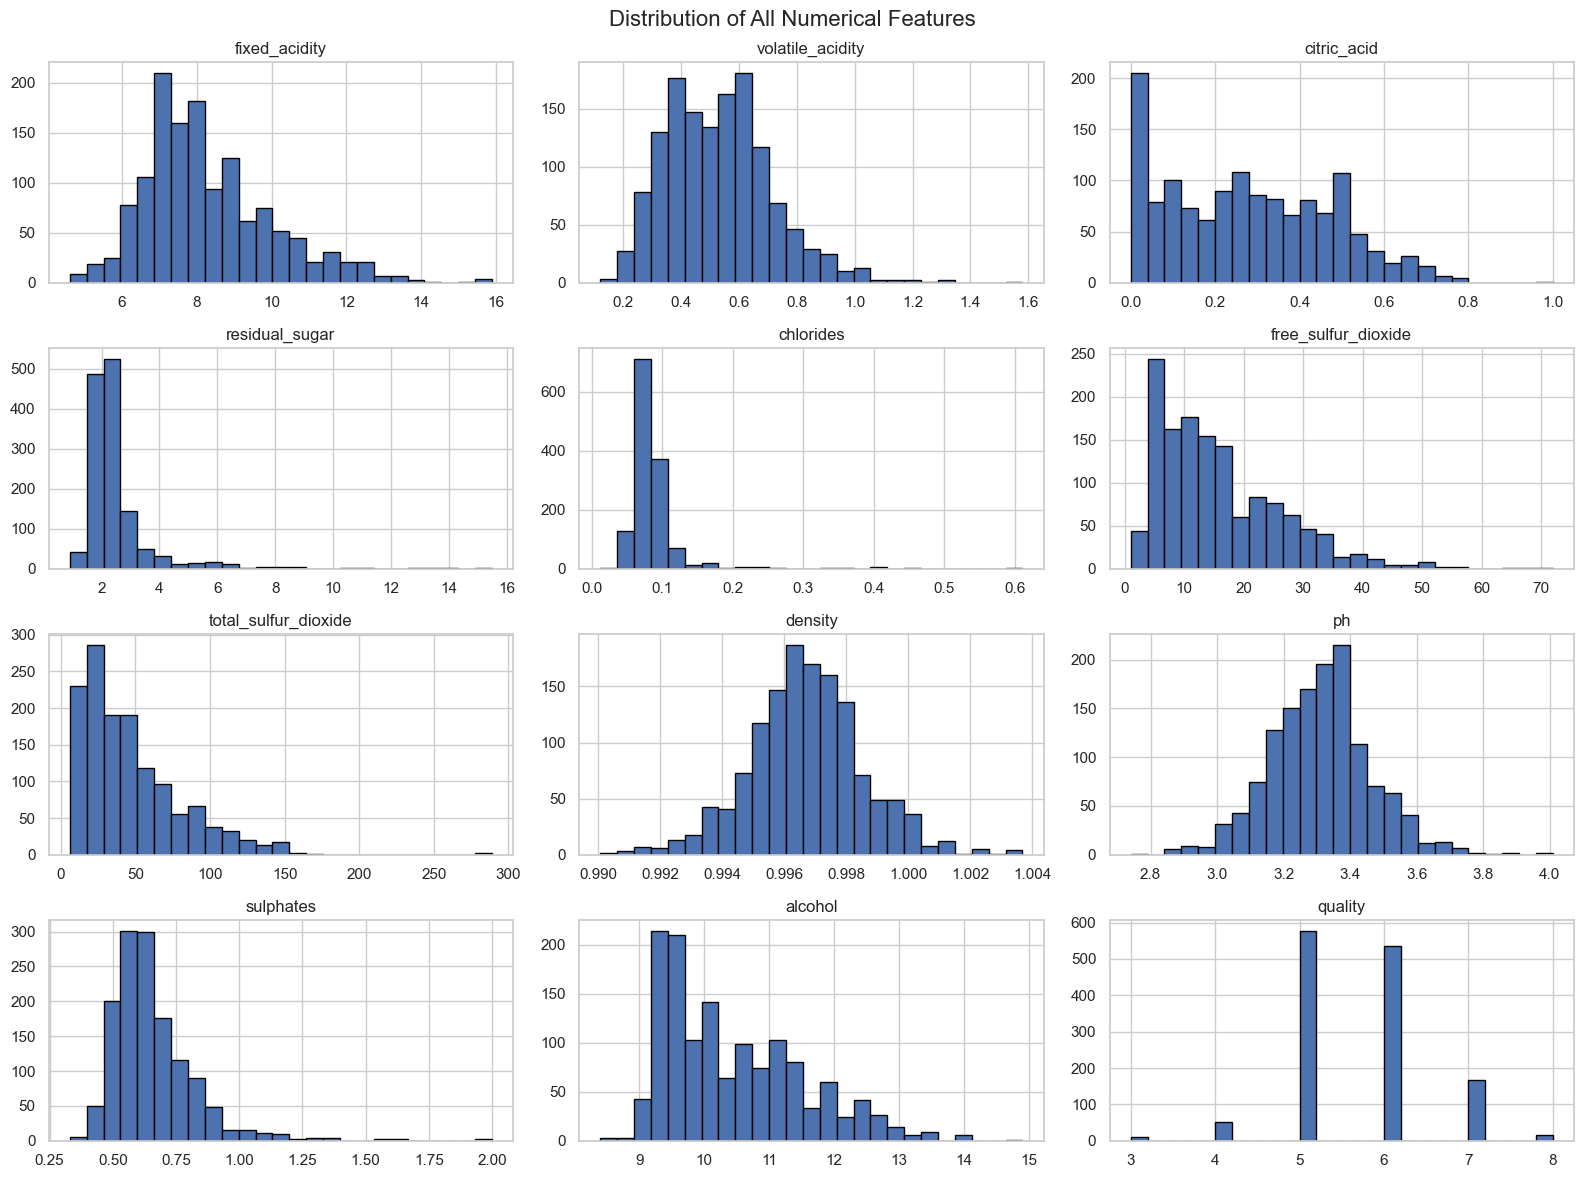

In [6]:
df.hist(
    figsize=(16, 12),
    bins=25,
    edgecolor="black"
)
plt.suptitle("Distribution of All Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

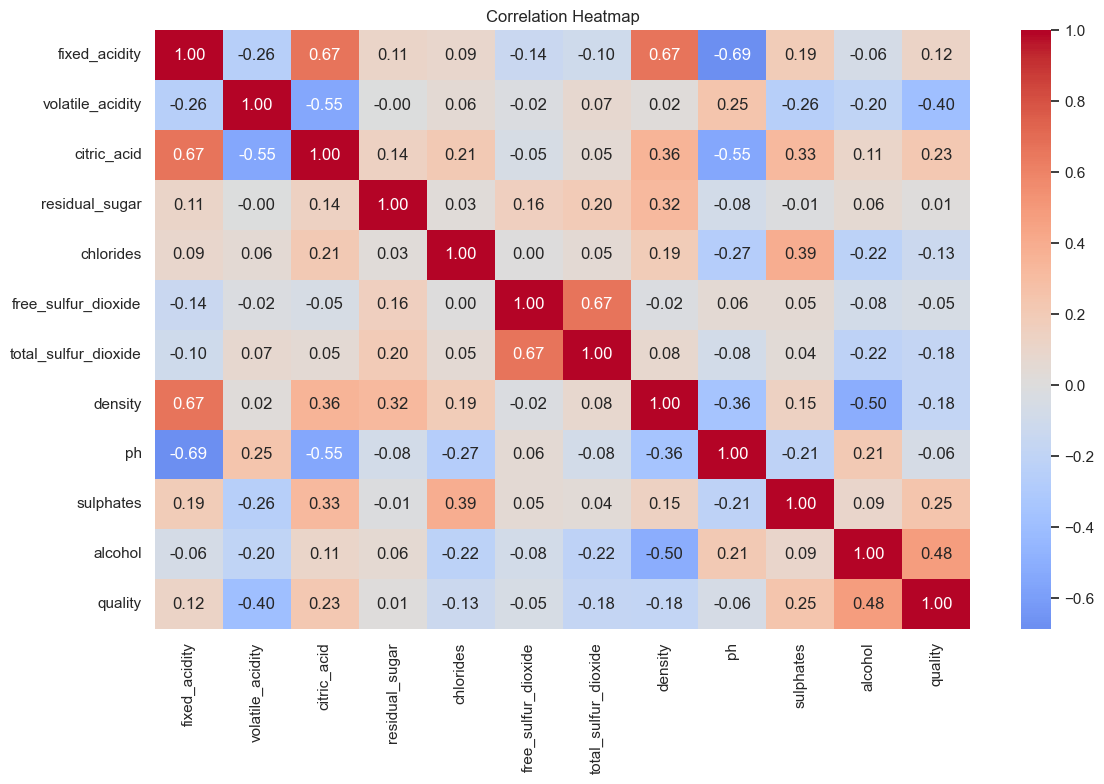

In [7]:
plt.figure(figsize=(12, 8))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

,Correlation with Quality
alcohol,0.480343
sulphates,0.248835
citric_acid,0.228057
fixed_acidity,0.119024
residual_sugar,0.013640
free_sulfur_dioxide,-0.050463
ph,-0.055245
chlorides,-0.130988
total_sulfur_dioxide,-0.177855
density,-0.184252


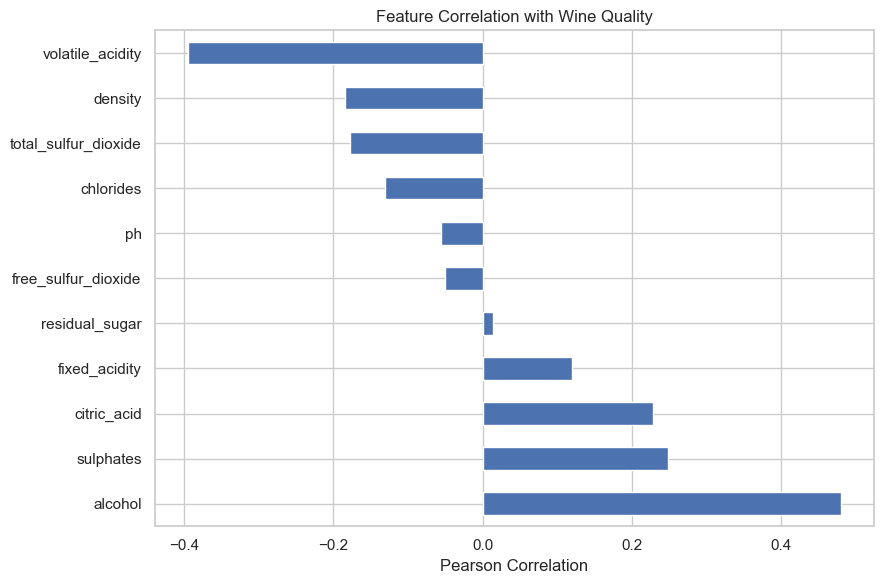

In [8]:
quality_corr = (
    correlation["quality"]
    .drop("quality")
    .sort_values(ascending=False)
)

display(quality_corr.to_frame("Correlation with Quality"))

plt.figure(figsize=(9, 6))
quality_corr.plot(kind="barh")
plt.title("Feature Correlation with Wine Quality")
plt.xlabel("Pearson Correlation")
plt.tight_layout()
plt.show()

In [9]:
X = df.drop(columns=["quality"])
y = df["quality"]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget variable: quality")

Feature matrix shape: (1359, 11)
Target vector shape: (1359,)

Input features:
['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'ph', 'sulphates', 'alcohol']

Target variable: quality


In [11]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=RANDOM_STATE)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training percentage:", round(len(X_train) / len(X) * 100, 2), "%")
print("Testing percentage:", round(len(X_test) / len(X) * 100, 2), "%")

Training samples: 1087
Testing samples: 272
Training percentage: 79.99 %
Testing percentage: 20.01 %


In [12]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])
model.fit(X_train, y_train)
print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [13]:
y_pred = model.predict(X_test)
predictions = pd.DataFrame({
    "Actual Quality": y_test.to_numpy(),
    "Predicted Quality": y_pred
})
predictions["Residual"] = (predictions["Actual Quality"] - predictions["Predicted Quality"])
predictions["Absolute Error"] = predictions["Residual"].abs()
display(predictions.head(10))

,Actual Quality,Predicted Quality,Residual,Absolute Error
0,5,5.245601,-0.245601,0.245601
1,6,5.809935,0.190065,0.190065
2,7,6.368405,0.631595,0.631595
3,5,5.158733,-0.158733,0.158733
4,4,5.199286,-1.199286,1.199286
5,7,6.776391,0.223609,0.223609
6,5,5.706717,-0.706717,0.706717
7,5,4.844757,0.155243,0.155243
8,6,5.799955,0.200045,0.200045
9,5,5.739405,-0.739405,0.739405


In [14]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
metrics = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R² Score"],
    "Value": [mae, mse, rmse, r2]
})
display(metrics.style.format({"Value": "{:.4f}"}))

,Metric,Value
0,MAE,0.5041
1,MSE,0.4310
2,RMSE,0.6565
3,R² Score,0.3915


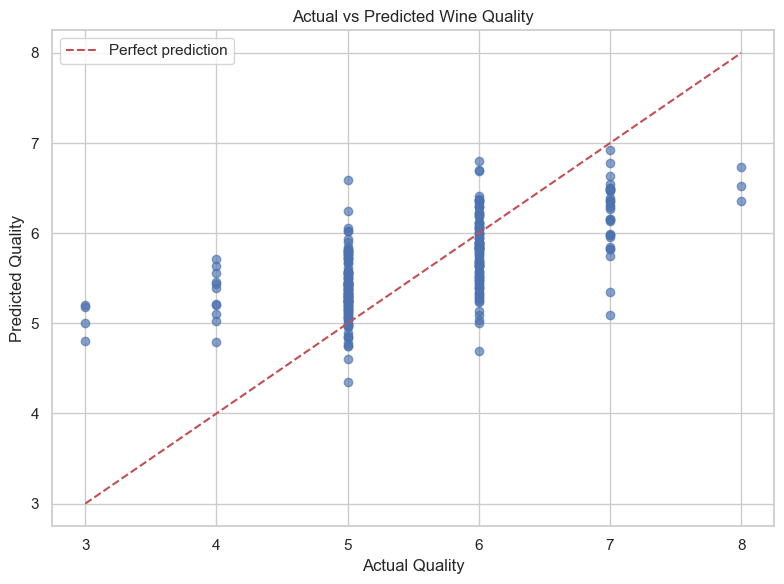

In [16]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.65)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high],[low, high],"r--",label="Perfect prediction")
plt.xlabel("Actual Quality")
plt.ylabel("Predicted Quality")
plt.title("Actual vs Predicted Wine Quality")
plt.legend()
plt.tight_layout()
plt.show()

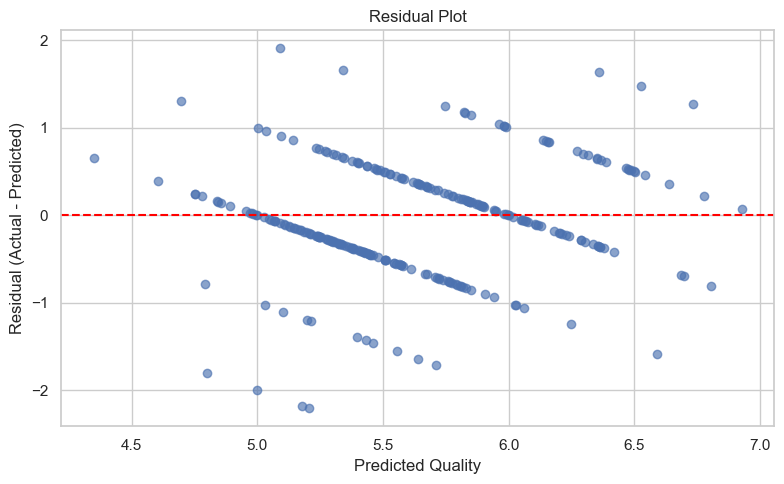

In [17]:
residuals = y_test.to_numpy() - y_pred
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.65)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Quality")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

,Feature,Coefficient,Absolute Magnitude
10,alcohol,0.333970,0.333970
1,volatile_acidity,-0.178494,0.178494
9,sulphates,0.148499,0.148499
6,total_sulfur_dioxide,-0.123600,0.123600
8,ph,-0.121548,0.121548
4,chlorides,-0.115971,0.115971
0,fixed_acidity,-0.049675,0.049675
5,free_sulfur_dioxide,0.048723,0.048723
7,density,0.042064,0.042064
2,citric_acid,-0.019148,0.019148


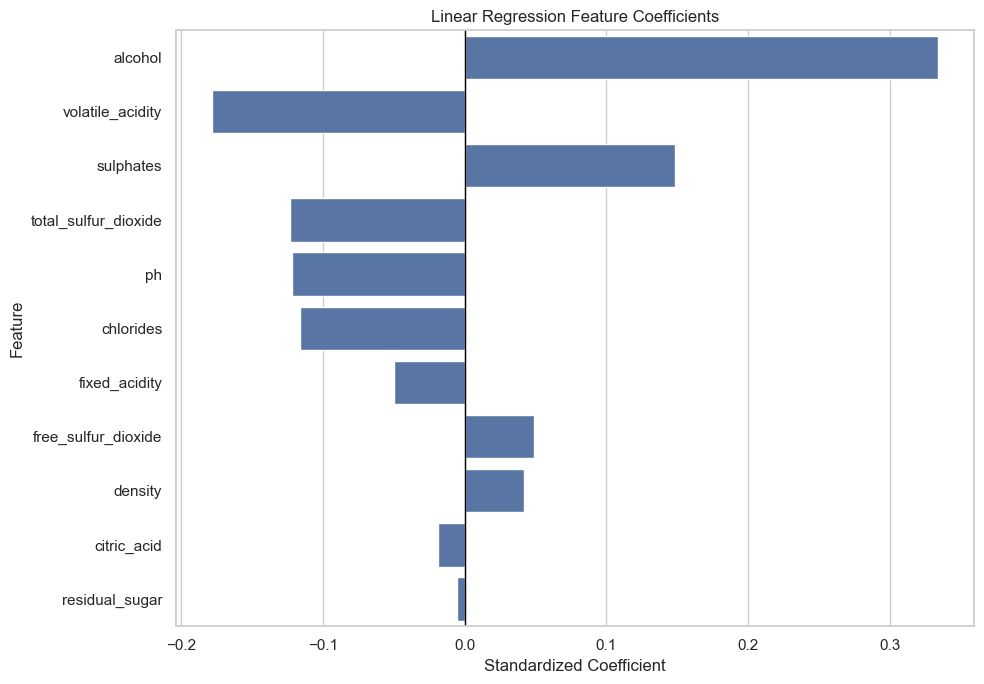

In [18]:
regressor = model.named_steps["regressor"]
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": regressor.coef_
})
coefficients["Absolute Magnitude"] = coefficients["Coefficient"].abs()
coefficients = coefficients.sort_values(
    "Absolute Magnitude",
    ascending=False
)
display(coefficients)
plt.figure(figsize=(10, 7))
sns.barplot(
    data=coefficients,
    x="Coefficient",
    y="Feature"
)
plt.axvline(0, color="black", linewidth=1)
plt.title("Linear Regression Feature Coefficients")
plt.xlabel("Standardized Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [19]:
largest_errors = predictions.sort_values(
    "Absolute Error",
    ascending=False
).head(10)

display(largest_errors)

,Actual Quality,Predicted Quality,Residual,Absolute Error
96,3,5.206672,-2.206672,2.206672
182,3,5.179357,-2.179357,2.179357
224,3,5.000125,-2.000125,2.000125
238,7,5.092275,1.907725,1.907725
135,3,4.800241,-1.800241,1.800241
175,4,5.710206,-1.710206,1.710206
128,7,5.342950,1.657050,1.657050
211,8,6.359389,1.640611,1.640611
151,4,5.639061,-1.639061,1.639061
122,5,6.591315,-1.591315,1.591315


In [20]:
print("=" * 50)
print("REGRESSRIGHT — PROJECT SUMMARY")
print("=" * 50)

print(f"Raw dataset rows: {len(df_raw):,}")
print(f"Rows after cleaning: {len(df):,}")
print(f"Input features: {X.shape[1]}")
print(f"Training samples: {len(X_train):,}")
print(f"Testing samples: {len(X_test):,}")

print("\nMODEL PERFORMANCE")
print(f"MAE:      {mae:.4f}")
print(f"MSE:      {mse:.4f}")
print(f"RMSE:     {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

print("\nModel: Multiple Linear Regression")
print("Status: Training and evaluation complete.")

REGRESSRIGHT — PROJECT SUMMARY
Raw dataset rows: 1,599
Rows after cleaning: 1,359
Input features: 11
Training samples: 1,087
Testing samples: 272

MODEL PERFORMANCE
MAE:      0.5041
MSE:      0.4310
RMSE:     0.6565
R² Score: 0.3915

Model: Multiple Linear Regression
Status: Training and evaluation complete.
